# HW2 · Single-stock risk report
**Yixiao Yang · parameterized report**

This notebook consumes `ohlc_hw_cleaned`, uses adjusted-close log returns, and exports named results through Scrapbook. It requires 21 prices for a full 20-return volatility window. Run `01_data_cleaning.ipynb` first. The cell below has the actual Papermill `parameters` metadata tag.

In [1]:
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"
dataset_label = "COURSE DATABASE"
run_id = "interactive"

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"
dataset_label = "COURSE DATABASE"
run_id = "be8d0396e747487a8ae69654b064d3d5"


## Data-loading functions

In [3]:
"""Shared risk calculations and Matplotlib figures used by the report notebook."""
from contextlib import closing
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter


GREEN, RED, NAVY, GRAY = '#16816a', '#d1495b', '#193b5a', '#9aa3ad'
from pathlib import Path
from html import unescape
import sqlite3

RAW = ['open', 'high', 'low', 'close']
PRICES = RAW + ['adj_close']
KEY = ['ticker', 'ts']

def normalize_ticker(value):
    """Remove vendor HTML/entities and whitespace, preserving ticker punctuation."""
    if pd.isna(value):
        return pd.NA
    value = re.sub(r'<[^>]*>', '', unescape(str(value)))
    value = re.sub(r'\s+', '', value).upper()
    return value if value else pd.NA


def validate_cleaned(frame):
    """Fail explicitly on invalid retained prices, volume, keys, dates or adjustment."""
    if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
        raise ValueError('Cleaned keys must be nonmissing and unique.')
    if frame.empty:
        return
    prices = frame[PRICES].to_numpy(float)
    if not np.isfinite(prices).all() or not (prices > 0).all():
        raise ValueError('Cleaned prices must be finite and positive.')
    if not frame['open'].between(frame['low'], frame['high']).all() or not frame['close'].between(frame['low'], frame['high']).all():
        raise ValueError('Cleaned OHLC bounds failed.')
    if not np.isfinite(frame['volume']).all() or frame['volume'].lt(0).any():
        raise ValueError('Volume must be finite and nonnegative.')
    if not np.allclose(frame['adj_close'], frame['close'] * frame['adjustment_factor'], rtol=1e-8):
        raise ValueError('Adjusted close is inconsistent with the recorded date-specific factor.')


def open_database(path, readonly=True):
    """Open an existing DB without accidentally creating an empty SQLite file."""
    path = Path(path).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}. Supply the bCourses data.db; no synthetic fallback.')
    return sqlite3.connect(path.as_uri() + ('?mode=ro' if readonly else '?mode=rw'), uri=True)


def validate_dates(start_date, end_date):
    """Require valid ISO calendar dates and a non-reversed inclusive interval."""
    for value in [start_date, end_date]:
        if not isinstance(value, str) or not re.fullmatch(r'\d{4}-\d{2}-\d{2}', value):
            raise ValueError('Dates must be YYYY-MM-DD strings.')
        pd.Timestamp(value)  # Reject impossible calendar dates.
    if start_date > end_date:
        raise ValueError('start_date must be on or before end_date.')


def load_stock(db_path, ticker, start_date, end_date):
    """Read validated cleaned data using SQL parameters; require 21 prices."""
    validate_dates(start_date, end_date)
    if not isinstance(ticker, str) or not ticker or normalize_ticker(ticker) != ticker:
        raise ValueError('ticker must be a nonempty normalized string.')
    with closing(open_database(db_path)) as conn:
        df = pd.read_sql_query(
            'SELECT * FROM ohlc_hw_cleaned WHERE ticker = ? AND ts >= ? AND ts <= ? ORDER BY ts',
            conn, params=(ticker, start_date, end_date), parse_dates=['ts'])
    if len(df) < 21:
        actual = 'no observations' if df.empty else f'{df.ts.min().date()} to {df.ts.max().date()}'
        raise ValueError(f'{ticker}: need at least 21 prices for 20 returns; got {len(df)} ({actual}).')
    validate_cleaned(df)
    return df.set_index('ts')

## Risk calculation functions

In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Daily log returns from positive adjusted prices; first observation stays NaN."""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Annualized rolling sample SD of daily log returns, requiring a full window."""
    if isinstance(window, bool) or not isinstance(window, int) or window < 2:
        raise ValueError('window must be an integer >= 2.')
    return returns.rolling(window, min_periods=window).std(ddof=1) * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown, not its running minimum; summary uses .min()."""
    return prices / prices.cummax() - 1


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Course Sharpe approximation: (252*mean(log return)-rf)/(sqrt(252)*SD).

    Fewer than two returns or effectively zero volatility produces NaN.
    """
    observed = returns.dropna()
    if not np.isfinite(observed).all():
        raise ValueError('Returns must be finite or missing.')
    sigma = observed.std(ddof=1)
    if len(observed) < 2 or not np.isfinite(sigma) or sigma <= np.finfo(float).eps * 10:
        return float('nan')
    return float((observed.mean() * 252 - risk_free_rate) / (sigma * np.sqrt(252)))


def enrich_stock(frame):
    """Add log returns, rolling volatility, full-window MA50 and recoverable drawdown."""
    df = frame.copy()
    df['log_return'] = calculate_returns(df['adj_close'])
    df['volatility_20'] = calculate_volatility(df['log_return'])
    df['ma_50'] = df['adj_close'].rolling(50, min_periods=50).mean()
    df['drawdown'] = calculate_max_drawdown(df['adj_close'])
    return df


def summary_metrics(df):
    """Ten required summary statistics, stored as fractions (Sharpe dimensionless)."""
    ret = df['log_return'].dropna()
    return {
        'Total Return': float(df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1),
        'Annualized Return': float(np.expm1(ret.sum() * 252 / len(ret))) if len(ret) else np.nan,
        'Annualized Volatility': float(ret.std(ddof=1) * np.sqrt(252)),
        'Sharpe Ratio': calculate_sharpe_ratio(ret),
        'Maximum Drawdown': float(df['drawdown'].min()),
        'Best Day': float(ret.max()),
        'Worst Day': float(ret.min()),
        'Positive Days': float(ret.gt(0).mean()) if len(ret) else np.nan,
        'Average Up Day': float(ret.loc[ret > 0].mean()),
        'Average Down Day': float(ret.loc[ret < 0].mean()),
    }


def formatted_summary(metrics):
    """Format display only; numeric export values retain fractional units."""
    return pd.DataFrame({'Metric': list(metrics), 'Value': [
        'N/A' if pd.isna(value) else f'{value:.2f}' if key == 'Sharpe Ratio' else f'{value:+.2%}'
        for key, value in metrics.items()]})


def report_outputs(df, ticker, start_date, end_date, dataset_label='COURSE DATABASE'):
    """Named scalar outputs for Scrapbook collection with explicit observed coverage."""
    metrics = summary_metrics(df)
    return {
        'ticker': ticker, 'start_date': start_date, 'end_date': end_date,
        'actual_start': df.index.min().strftime('%Y-%m-%d'),
        'actual_end': df.index.max().strftime('%Y-%m-%d'),
        'trading_days': int(len(df)), 'return_count': int(df['log_return'].count()),
        'avg_daily_return': float(df['log_return'].mean()),
        'avg_volatility': float(df['volatility_20'].mean()),
        'max_drawdown': metrics['Maximum Drawdown'], 'sharpe_ratio': metrics['Sharpe Ratio'],
        'total_return': metrics['Total Return'], 'annualized_return': metrics['Annualized Return'],
        'annualized_volatility': metrics['Annualized Volatility'],
        'data_quality_ok': True, 'dataset_label': dataset_label,
        'repaired_price_rows': int(df['raw_price_repaired'].astype(bool).sum()),
        'repaired_adj_close_rows': int(df['adj_close_repaired'].astype(bool).sum()),
        'unknown_volume_rows': int(df['volume_unknown'].astype(bool).sum()),
    }

## Four-panel visualization function

In [5]:
def plot_stock(df, ticker, start_date, end_date, dataset_label='COURSE DATABASE'):
    """Required 16x12 four-panel report, preserving unavailable rolling estimates."""
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                         'axes.spines.top': False, 'axes.spines.right': False})
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.patch.set_facecolor('#f6f8fb')
    fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}',
                 fontsize=19, fontweight='bold', color=NAVY, y=.975)
    fig.text(.5, .94, f'{dataset_label}  |  Observed {df.index.min():%Y-%m-%d} to '
             f'{df.index.max():%Y-%m-%d}  |  {len(df)} prices / {df.log_return.count()} returns',
             ha='center', color='#526273', fontsize=11)
    dates, price, vol = df.index, df['adj_close'], df['volatility_20']
    mean_vol = vol.mean()
    ax = axes[0, 0]
    for i in range(1, len(df)):
        v = vol.iloc[i]
        color = GRAY if pd.isna(v) else RED if v > mean_vol else GREEN
        ax.plot(dates[i-1:i+1], price.iloc[i-1:i+1], color=color, linewidth=1.9)
    ax.plot(dates, df['ma_50'], color=NAVY, linestyle='--', linewidth=1.6)
    handles = [Line2D([0], [0], color=c, label=s, linestyle=ls) for c, s, ls in [
        (GREEN, 'Low/equal volatility', '-'), (RED, 'High volatility', '-'),
        (GRAY, 'Warm-up unavailable', '-'), (NAVY, '50-day MA', '--')]]
    ax.legend(handles=handles, fontsize=8, ncol=2, loc='best', frameon=False)
    if len(df) < 50:
        ax.text(.02, .02, 'MA50 unavailable: fewer than 50 prices', transform=ax.transAxes, fontsize=9)
    ax.set(title=f'{ticker} Price and 50-day MA', ylabel='Adjusted close (price units)')
    ax = axes[0, 1]
    ret = df['log_return']
    ax.bar(dates, ret, width=1.1, color=np.where(ret.ge(0), GREEN, RED), alpha=.85)
    ax.axhline(0, color=NAVY, linewidth=.7)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=f'{ticker} Daily Returns', ylabel='Daily log return')
    if ret.dropna().eq(0).all():
        ax.set_ylim(-.01, .01)
    ax = axes[1, 0]
    ax.plot(dates, vol, color=NAVY, linewidth=1.8, label='20-return sample volatility')
    ax.axhline(mean_vol, color='#7e6b9b', linestyle='--', label=f'Mean {mean_vol:.2%}')
    for condition, color in [(vol.gt(mean_vol), RED), (vol.lt(mean_vol), GREEN)]:
        ax.fill_between(dates, vol, mean_vol, where=condition & vol.notna(),
                        color=color, alpha=.2, interpolate=True)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=f'{ticker} Rolling Volatility (20-day)', ylabel='Annualized volatility')
    ax.legend(frameon=False, fontsize=9)
    if vol.dropna().eq(0).all():
        ax.set_ylim(0, .01)
        ax.text(.02, .87, 'Observed rolling volatility is zero', transform=ax.transAxes, fontsize=9)
    ax = axes[1, 1]
    dd = df['drawdown']
    for fraction in [1, .8, .6, .4, .2]:
        ax.fill_between(dates, dd * fraction, 0, color=RED, alpha=.16)
    ax.plot(dates, dd, color=RED, linewidth=1)
    worst = dd.idxmin()
    ax.scatter([worst], [dd.loc[worst]], color=NAVY, s=45, zorder=4)
    early = worst <= dates[len(dates)//3]
    ax.annotate(f'Max {dd.loc[worst]:.2%}\n{worst:%Y-%m-%d}',
                (worst, dd.loc[worst]), xytext=(8 if early else -8, 18), textcoords='offset points',
                ha='left' if early else 'right', fontsize=9, color=NAVY)
    ax.axhline(0, color=NAVY, linewidth=.7)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=f'{ticker} Maximum Drawdown', ylabel='Drawdown from running peak')
    ax.margins(y=.22)
    if dd.eq(0).all():
        ax.set_ylim(-.01, .005)
    for ax in axes.flat:
        locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.set_xlabel('Observation date')
        ax.grid(True, alpha=.18)
        ax.set_axisbelow(True)
        ax.set_facecolor('white')
        ax.set_xlim(dates[0] - pd.Timedelta(days=1), dates[-1] + pd.Timedelta(days=1))
    fig.text(.06, .025, 'Adjusted-price log returns; 252 sessions/year; risk-free rate 2%. '
             'Color threshold is retrospective. Coverage differs across stocks.', fontsize=10, color='#526273')
    fig.subplots_adjust(top=.88, bottom=.09, hspace=.31, wspace=.21)
    return fig

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scrapbook as sb
from IPython.display import display, Markdown
%matplotlib inline
print("DATASET:", dataset_label)
df = load_stock(db_path, ticker, start_date, end_date)
print(f"{ticker} from {start_date} to {end_date}: {len(df)} trading days")
print(f"Actual observations: {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}")
display(df.head())
display(df.tail())
print("Requested dates do not guarantee observed coverage; no trailing prices are extrapolated.")
if len(df) < 50:
    print("50-day MA unavailable: fewer than 50 prices. Available data are still shown.")

No event loop hook running.
DATASET: COURSE DATABASE
IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual observations: 2024-06-03 to 2024-11-29
Requested dates do not guarantee observed coverage; no trailing prices are extrapolated.


,source_row_id,ticker,open,high,low,close,adj_close,volume,ticker_original,...,volume_unknown,raw_price_repaired,close_repaired,adj_close_repaired,extreme_return_before,outlier_decision,repair_flags,return_affected_by_repair,extreme_return_after
ts,,,,,,,,,,,,,,,,,,,
2024-06-03,176093,IBM,166.54,166.78,163.53,165.28,162.57,2776100.0,IBM,...,0,0,0,0,0,not_flagged,[],0,0
2024-06-04,187151,IBM,164.60,166.40,163.88,165.81,163.09,2594203.0,IBM,...,0,0,0,0,0,not_flagged,[],0,0
2024-06-05,206768,IBM,166.41,167.79,165.78,167.38,164.63,3049400.0,IBM,...,0,0,0,0,0,not_flagged,[],0,0
2024-06-06,281788,IBM,167.38,168.44,166.80,168.20,165.44,2207263.0,IBM,...,0,0,0,0,0,not_flagged,[],0,0
2024-06-07,389325,IBM,168.18,171.31,168.06,170.01,167.22,3475500.0,IBM,...,0,0,0,0,0,not_flagged,[],0,0


,source_row_id,ticker,open,high,low,close,adj_close,volume,ticker_original,...,volume_unknown,raw_price_repaired,close_repaired,adj_close_repaired,extreme_return_before,outlier_decision,repair_flags,return_affected_by_repair,extreme_return_after
ts,,,,,,,,,,,,,,,,,,,
2024-11-22,27517,IBM,223.35,227.20,220.89,222.97,222.97,5320740.0,IBM,...,0,0,0,0,0,not_flagged,[],0,0
2024-11-25,353750,IBM,223.35,226.42,222.65,226.13,226.13,7189300.0,IBM,...,0,0,0,0,0,not_flagged,[],0,0
2024-11-26,391137,IBM,226.73,228.98,225.51,228.83,228.83,4449543.0,"<a target=""_blank""><span style=""font-weight: b...",...,0,0,0,0,0,not_flagged,[],0,0
2024-11-27,122547,IBM,228.83,229.19,224.27,226.92,226.92,2995121.0,IBM,...,0,0,0,0,0,not_flagged,[],0,0
2024-11-29,321741,IBM,227.75,230.36,227.19,227.41,227.41,2640300.0,IBM,...,0,0,0,0,0,not_flagged,[],0,0


## Risk conventions and functions
All functions and their docstrings are included in the cells above.

- Log return: $r_t=\log(P_t/P_{t-1})$, using **adjusted close**; the initial missing return is not zero.
- 20-return volatility: sample $s_{20}(r)\sqrt{252}$; first estimate requires **21 prices**.
- Drawdown: $P_t/\max_{s\le t}P_s-1$, which can recover. Maximum drawdown is its minimum.
- Sharpe: $(252\bar r-0.02)/(s(r)\sqrt{252})$, the course approximation. Insufficient/zero variance gives `N/A`.
- Total return: $P_{last}/P_{first}-1$; compounded annualized return: $\exp(252\sum r/n)-1$.

Whole-period annualized volatility differs from the **mean rolling volatility** exported to the portfolio dashboard. The price-line threshold is the report-wide mean rolling volatility, so coloring is retrospective.

In [7]:
# Independent sanity checks of conventions.
check_prices = pd.Series([80., 100., 70., 85.])
np.testing.assert_allclose(calculate_max_drawdown(check_prices), [0., 0., -.3, -.15])
np.testing.assert_allclose(calculate_returns(pd.Series([100., 110., 99.])).iloc[1:], np.log([1.1, .9]))
assert np.isnan(calculate_sharpe_ratio(pd.Series([0., 0., 0.])))
df = enrich_stock(df)
assert df.volatility_20.iloc[:20].isna().all()
assert df.ma_50.iloc[:min(49, len(df))].isna().all()
display(df[['adj_close','log_return','volatility_20','ma_50','drawdown']].tail())

,adj_close,log_return,volatility_20,ma_50,drawdown
ts,,,,,
2024-11-22,222.97,0.002560,0.241515,218.0336,-0.044769
2024-11-25,226.13,0.014073,0.241623,218.2470,-0.031231
2024-11-26,228.83,0.011869,0.236457,218.5744,-0.019664
2024-11-27,226.92,-0.008382,0.212190,218.8476,-0.027847
2024-11-29,227.41,0.002157,0.212125,219.1514,-0.025748


## Risk dashboard
Gray price segments indicate unavailable rolling estimates. Red/green indicate volatility above/at-or-below the report-wide mean. Signed daily-return bars and the recoverable drawdown use the same return basis. The maximum drawdown marker refers only to this observed window.

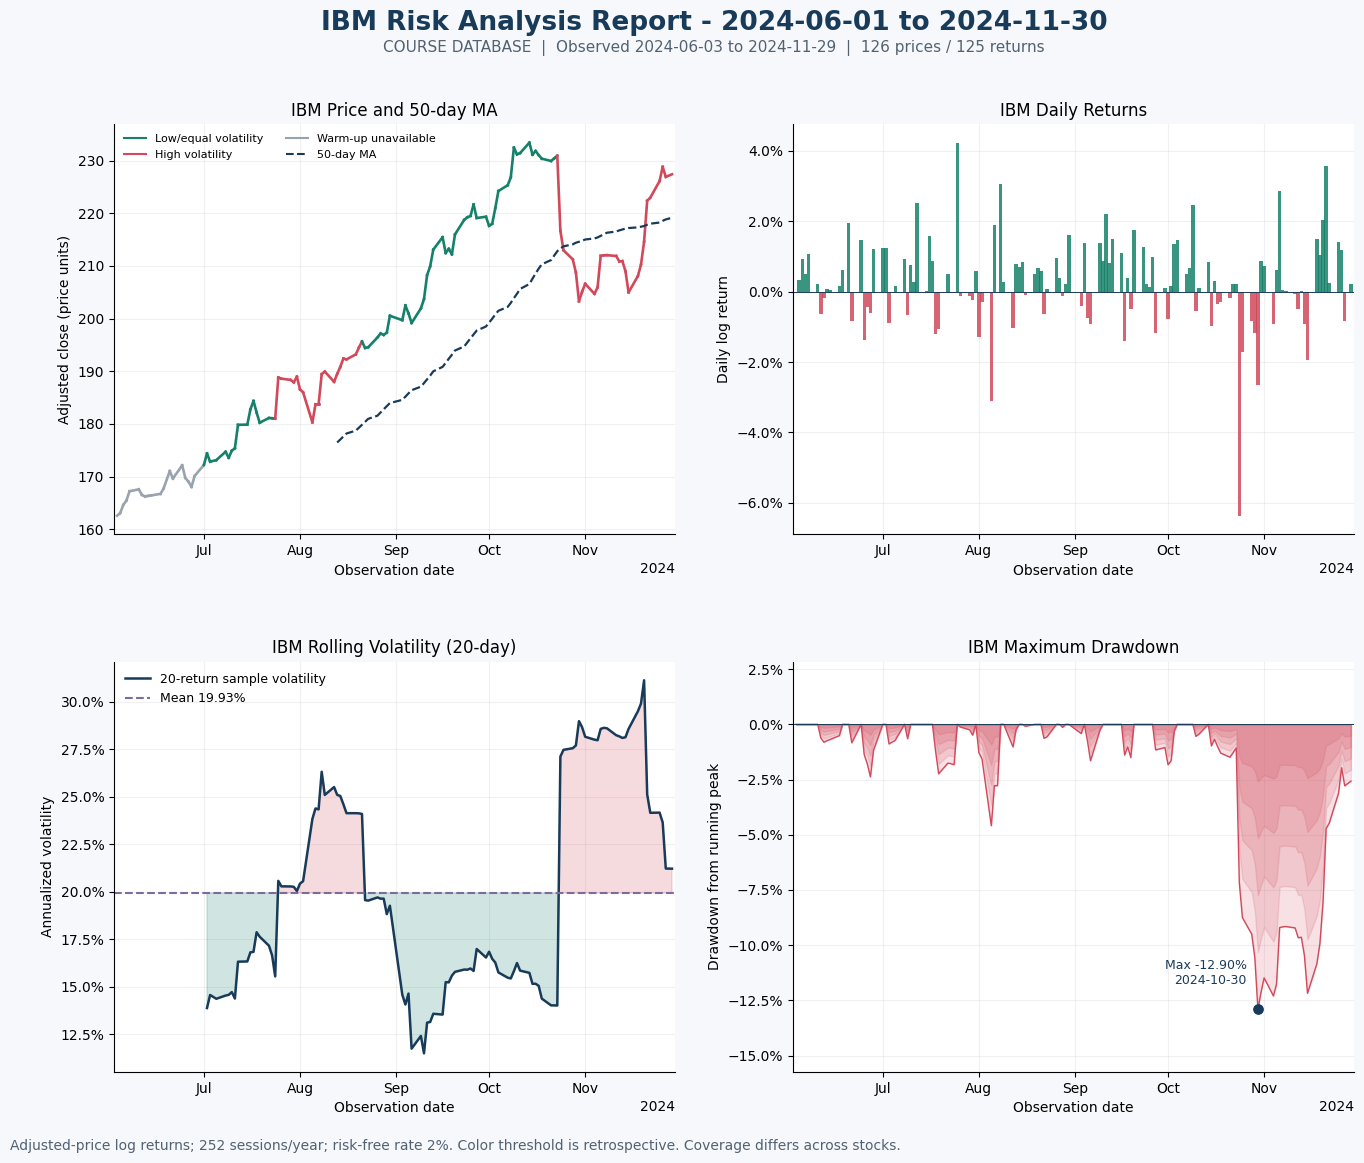

In [8]:
fig = plot_stock(df, ticker, start_date, end_date, dataset_label)
plt.show()

## Summary statistics
Best/worst days and average up/down days are **log returns**. Positive days divide by all nonmissing returns, including zero days. Empty sign subsets and undefined Sharpe display `N/A`. Display formatting does not change the fractional values exported to CSV.

In [9]:
metrics = summary_metrics(df)
display(formatted_summary(metrics))
print("Mean rolling annualized volatility (dashboard X):", f"{df.volatility_20.mean():.2%}")
print("Whole-period annualized volatility:", f"{metrics['Annualized Volatility']:.2%}")
print("Repair provenance in requested window:")
display(df[['raw_price_repaired','adj_close_repaired','volume_unknown',
            'extreme_return_before','extreme_return_after']].astype(bool).sum().rename('rows').to_frame())
print("Observed intervals can span missing sessions. No unobserved prices are manufactured;")
print("252-day annualization assumes each available return is one session, so gaps can distort it.")

Mean rolling annualized volatility (dashboard X): 19.93%
Whole-period annualized volatility: 20.42%
Repair provenance in requested window:
Observed intervals can span missing sessions. No unobserved prices are manufactured;
252-day annualization assumes each available return is one session, so gaps can distort it.


,Metric,Value
0,Total Return,+39.88%
1,Annualized Return,+96.73%
2,Annualized Volatility,+20.42%
3,Sharpe Ratio,3.22
4,Maximum Drawdown,-12.90%
5,Best Day,+4.24%
6,Worst Day,-6.37%
7,Positive Days,+63.20%
8,Average Up Day,+0.95%
9,Average Down Day,-0.92%


,rows
raw_price_repaired,0
adj_close_repaired,8
volume_unknown,0
extreme_return_before,1
extreme_return_after,1


## Named outputs for automation
One `report_metrics` object and a run identifier are exported. The batch collector reads only newly successful paths, checks these identities, and ignores failed/stale notebook files. Relative `report_path` values in the CSV resolve from its directory. Unequal observed histories limit direct stock rankings.

In [10]:
outputs = report_outputs(df, ticker, start_date, end_date, dataset_label)
sb.glue('report_metrics', outputs, encoder='json')
sb.glue('run_id', run_id)
print("Named metrics exported successfully.")
plt.close(fig)

Named metrics exported successfully.


/root/.local/lib/python3.12/site-packages/scrapbook/utils.py:64: UserWarning: No kernel detected for 'glue'.
  warnings.warn("No kernel detected for '{fname}'.".format(fname=f.__name__))
